In [1]:
import h2py
from h2py.utils import timestamp
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pickle


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [3]:
# Dynamic path specification
example = "path/to/files_chr{chrom}.pkl"
print(example.format(chrom=1))

path/to/files_chr1.pkl


In [4]:
def run_bootstrap(path_spec):
    data = {}
    for chrom in range(1, 23):
        chrom_file = path_spec.format(chrom=chrom)
        with open(chrom_file, "rb") as fin:
            chrom_data = pickle.load(fin)
            for x in chrom_data:
                if np.sum(chrom_data[x]["denoms"][:-1]) > 0:
                    data[x] = chrom_data[x]
    u_bar, n_sites = h2py.parsing.compute_avg_u(data)
    print(timestamp(), f"loaded {path_spec}")
    print(timestamp(), f"u_bar = {u_bar:.6}")
    print(timestamp(), f"L = {n_sites}")
    fac = u_bar ** 2
    for label in data:
        for i in range(len(data[label]["sums"]) - 1):
            data[label]["sums"][i] *= fac
        data[label]["sums"][-1] *= u_bar
    boot_h2 = h2py.parsing.bootstrap_data(data)
    reps = h2py.parsing.get_bootstrap_replicates(data)
    print(timestamp(), "\tfinished!")
    return boot_h2, reps


def run_bootstrap_without_adj(path_spec):
    data = {}
    for chrom in range(1, 23):
        chrom_file = path_spec.format(chrom=chrom)
        with open(chrom_file, "rb") as fin:
            chrom_data = pickle.load(fin)
        data.update(chrom_data)
    n_sites = np.sum([data[x]["denoms"][-1] for x in data])
    print(timestamp(), f"loaded {path_spec}")
    print(timestamp(), f"L = {n_sites}")
    boot_h2 = h2py.parsing.bootstrap_data(data)
    reps = h2py.parsing.get_bootstrap_replicates(data)
    print(timestamp(), "\tfinished!")
    return boot_h2, reps

In [5]:
masks = [
    "accessible_1e-3M_ccds_flank",
]

for rmap in ["bherer", "zhou-JHS"]:
    for mask in masks:
        data, reps = run_bootstrap(f"outputs/stats_{mask}_{rmap}_chr_{{chrom}}.pkl")
        with open(f"bootstrapped_data/{mask}_{rmap}_adj.pkl", "wb") as fout:
            pickle.dump(data, fout)

        rep_data = {"varcovs": data["varcovs"], "bins": data["bins"], "pops": data["pops"], "bootreps": reps}
        with open(f"bootstrapped_data/{mask}_{rmap}_adj_boot_reps.pkl", "wb") as fout:
            pickle.dump(rep_data, fout)

[26-10-11 21:28:26] loaded outputs/stats_accessible_1e-3M_ccds_flank_bherer_chr_{chrom}.pkl
[26-10-11 21:28:26] u_bar = 1.13084e-08
[26-10-11 21:28:26] L = 382191381.0
[26-10-11 21:28:56] 	finished!
[26-10-11 21:28:56] loaded outputs/stats_accessible_1e-3M_ccds_flank_zhou-JHS_chr_{chrom}.pkl
[26-10-11 21:28:56] u_bar = 1.13084e-08
[26-10-11 21:28:56] L = 382191160.0
[26-10-11 21:29:25] 	finished!


In [4]:
masks = [
    "accessible",
    "accessible_intergenic",
    "accessible_10kb_ccds_flank",
    "accessible_100kb_ccds_flank",
    "accessible_1e-4M_ccds_flank",
    "accessible_1e-3M_ccds_flank",
]
mask_subset = [masks[0], masks[1], masks[4]]

for rmap in ["bherer", "zhou-JHS"]:
    for mask in masks:
        data, reps = run_bootstrap(f"outputs/stats_{mask}_{rmap}_chr_{{chrom}}.pkl")
        with open(f"bootstrapped_data/{mask}_{rmap}_adj.pkl", "wb") as fout:
            pickle.dump(data, fout)

        rep_data = {"varcovs": data["varcovs"], "bins": data["bins"], "pops": data["pops"], "bootreps": reps}
        with open(f"bootstrapped_data/{mask}_{rmap}_adj_boot_reps.pkl", "wb") as fout:
            pickle.dump(rep_data, fout)
            
        data, _ = run_bootstrap_without_adj(f"outputs_without_adj/stats_{mask}_{rmap}_chr_{{chrom}}.pkl")
        with open(f"bootstrapped_data/{mask}_{rmap}_naive.pkl", "wb") as fout:
            pickle.dump(data, fout)
    
    
for rmap in ["omni-YRI", "pyrho-YRI"]:
    for mask in mask_subset:
        data, _ = run_bootstrap(f"outputs/stats_{mask}_{rmap}_chr_{{chrom}}.pkl")
        with open(f"bootstrapped_data/{mask}_{rmap}_adj.pkl", "wb") as fout:
            pickle.dump(data, fout)
            
        data, _ = run_bootstrap_without_adj(f"outputs_without_adj/stats_{mask}_{rmap}_chr_{{chrom}}.pkl")
        with open(f"bootstrapped_data/{mask}_{rmap}_naive.pkl", "wb") as fout:
            pickle.dump(data, fout)

[26-09-20 10:38:03] loaded outputs/stats_accessible_bherer_chr_{chrom}.pkl
[26-09-20 10:38:03] u_bar = 1.10763e-08
[26-09-20 10:38:03] L = 1156452083.0
[26-09-20 10:38:37] 	finished!
[26-09-20 10:38:37] loaded outputs_without_adj/stats_accessible_bherer_chr_{chrom}.pkl
[26-09-20 10:38:37] L = 1156452089.0
[26-09-20 10:39:10] 	finished!
[26-09-20 10:39:10] loaded outputs/stats_accessible_intergenic_bherer_chr_{chrom}.pkl
[26-09-20 10:39:10] u_bar = 1.10349e-08
[26-09-20 10:39:10] L = 1141551108.0
[26-09-20 10:39:44] 	finished!
[26-09-20 10:39:44] loaded outputs_without_adj/stats_accessible_intergenic_bherer_chr_{chrom}.pkl
[26-09-20 10:39:44] L = 1141551114.0
[26-09-20 10:40:18] 	finished!
[26-09-20 10:40:18] loaded outputs/stats_accessible_1e-4M_ccds_flank_bherer_chr_{chrom}.pkl
[26-09-20 10:40:18] u_bar = 1.12212e-08
[26-09-20 10:40:18] L = 662995352.0
[26-09-20 10:40:53] 	finished!
[26-09-20 10:40:54] loaded outputs_without_adj/stats_accessible_1e-4M_ccds_flank_bherer_chr_{chrom}.pkl

In [18]:
graph = "../../models/main_models/zhou_full.yaml"
pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
# data = h2py.parsing.subset_data(_data, to_pops=pops)
bins = h2py.parsing._get_bin_tuples(np.logspace(-6, -2, 17))
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=bins, sampled_demes=pops)

In [20]:
with open(f"bootstrapped_data/accessible_1e-4M_ccds_flank_zhou-JHS_adj.pkl", "rb") as fin:
    data = pickle.load(fin)
data = h2py.parsing.subset_data(data, to_pops=pops)
data["pops"]

['Altai',
 'Vindija',
 'Chagyrskaya',
 'Denisova',
 'Stuttgart',
 'Loschbour',
 'UstIshim',
 'Yoruba1']

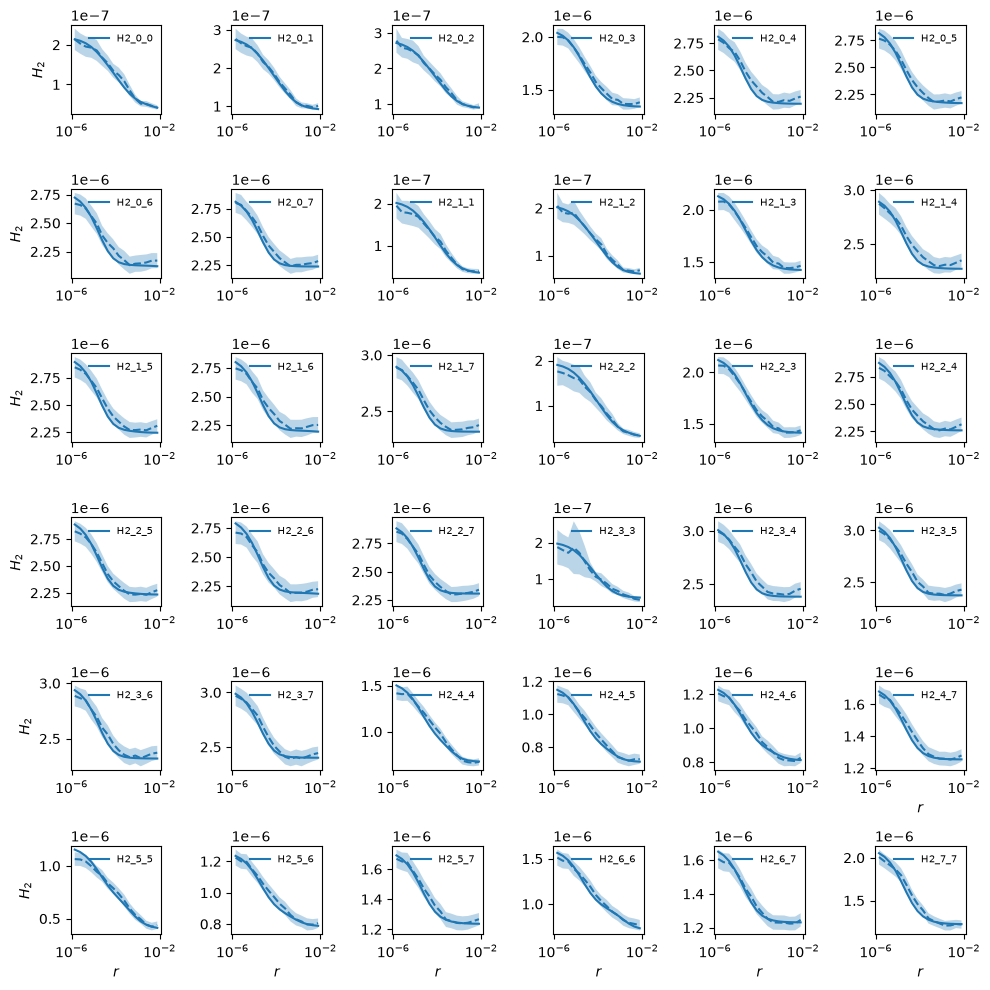

In [21]:
x = h2py.plotting.plot_h2_curves_comp(
    model,
    data["means"],
    data["varcovs"],
    fig_size=(10, 10),
    pops=pops,
    rows=6, cols=6,
    r_bins=bins #data["bins"],
)

In [5]:
h2py.inference._compute_composite_ll(model, data["means"], data["varcovs"])

NameError: name 'model' is not defined

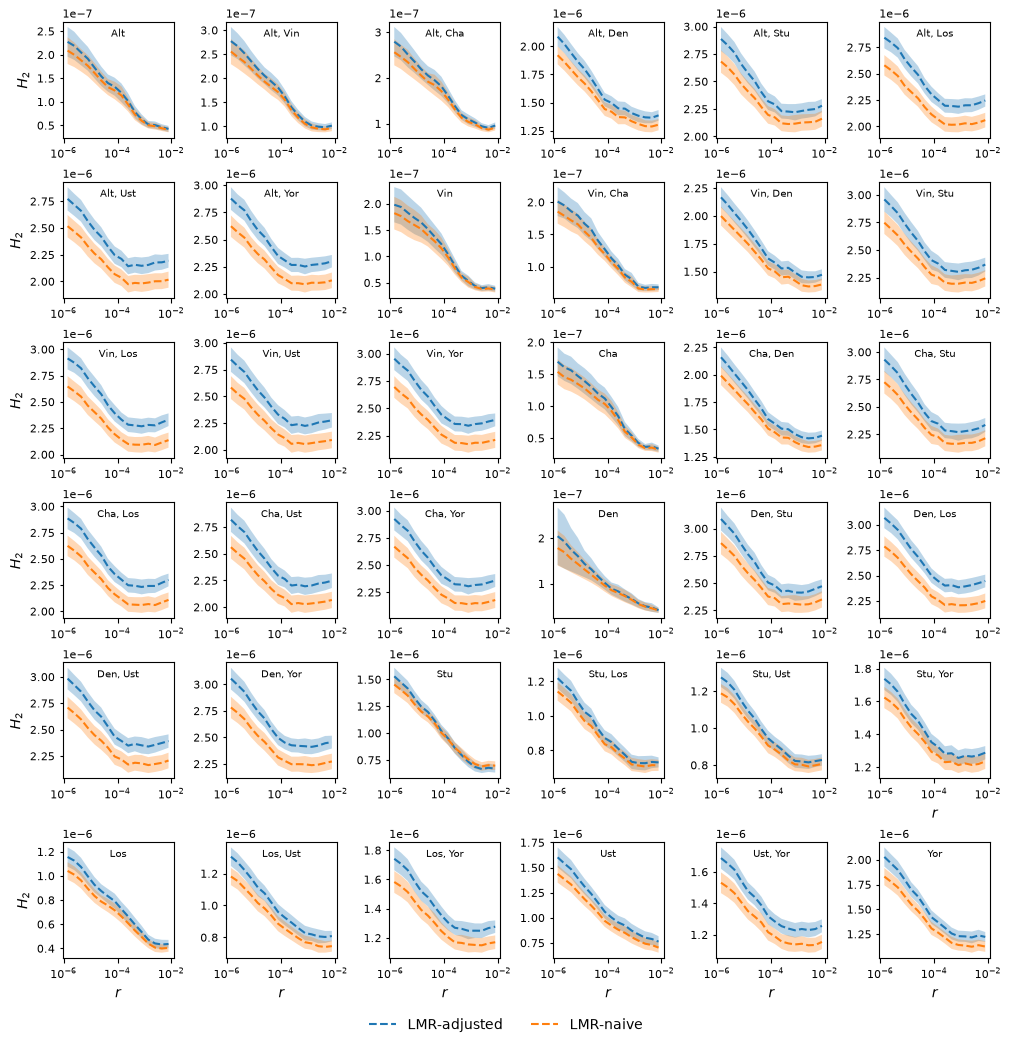

In [4]:
# mutation adjustment figure
mpl.rcParams["font.size"] = 10
mpl.rcParams['xtick.labelsize'] = 8
mpl.rcParams['ytick.labelsize'] = 8
mpl.rcParams['ytick.major.size'] = 2


pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
stat_labels = []
for i in range(8):
    stat_labels.append(pops[i][:3])
    for j in range(i + 1, 8):
        stat_labels.append(f"{pops[i][:3]}, {pops[j][:3]}")

stats = {}
for var in ["adj", "naive"]:
    with open(f"bootstrapped_data/accessible_1e-4M_ccds_flank_bherer_{var}.pkl", "rb") as fin:
        stat = pickle.load(fin)
        stats[var] = h2py.parsing.subset_data(stat, to_pops=pops)


h2py.plotting.plot_h2_curves(
    means=[stats[x]["means"] for x in stats],
    varcovs=[stats[x]["varcovs"] for x in stats],
    stat_labels=stat_labels,
    data_labels=["LMR-adjusted", "LMR-naive"],
    stats=stats[next(iter(stats))]["stats"][0],
    pops=stats[next(iter(stats))]["pops"],
    r_bins=stats[next(iter(stats))]["bins"],
    fig_size=(10,10),
    out_file="figures/LMR_adjustment.pdf"
)

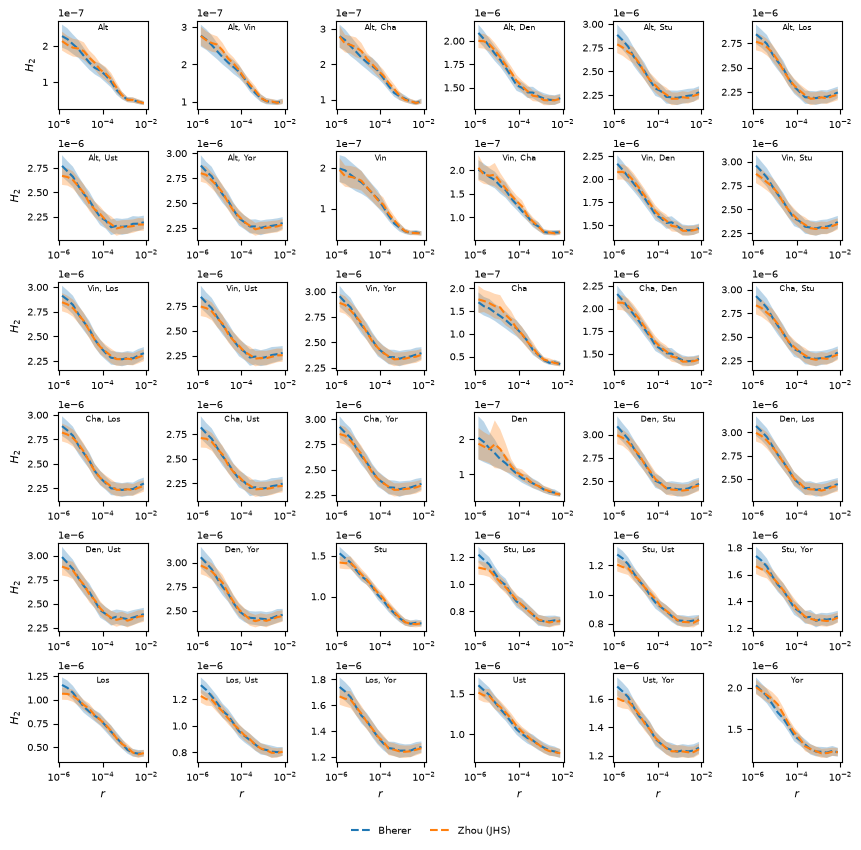

In [9]:
# recombination map figure

pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
stat_labels = []
for i in range(8):
    stat_labels.append(pops[i][:3])
    for j in range(i + 1, 8):
        stat_labels.append(f"{pops[i][:3]}, {pops[j][:3]}")

stats = {}
for var in ["bherer", "zhou-JHS"]:
    with open(f"bootstrapped_data/accessible_1e-4M_ccds_flank_{var}_adj.pkl", "rb") as fin:
        stat = pickle.load(fin)
        stats[var] = h2py.parsing.subset_data(stat, to_pops=pops)


h2py.plotting.plot_h2_curves(
    means=[stats[x]["means"] for x in stats],
    varcovs=[stats[x]["varcovs"] for x in stats],
    stat_labels=stat_labels,
    colors=["tab:blue", "tab:orange", "tab:green"],
    data_labels=["Bherer", "Zhou (JHS)"],
    stats=stats[next(iter(stats))]["stats"][0],
    pops=stats[next(iter(stats))]["pops"],
    r_bins=stats[next(iter(stats))]["bins"],
    fig_size=(8.5, 8.),
    out_file="../../figures/bherer_zhou_maps.pdf"
)

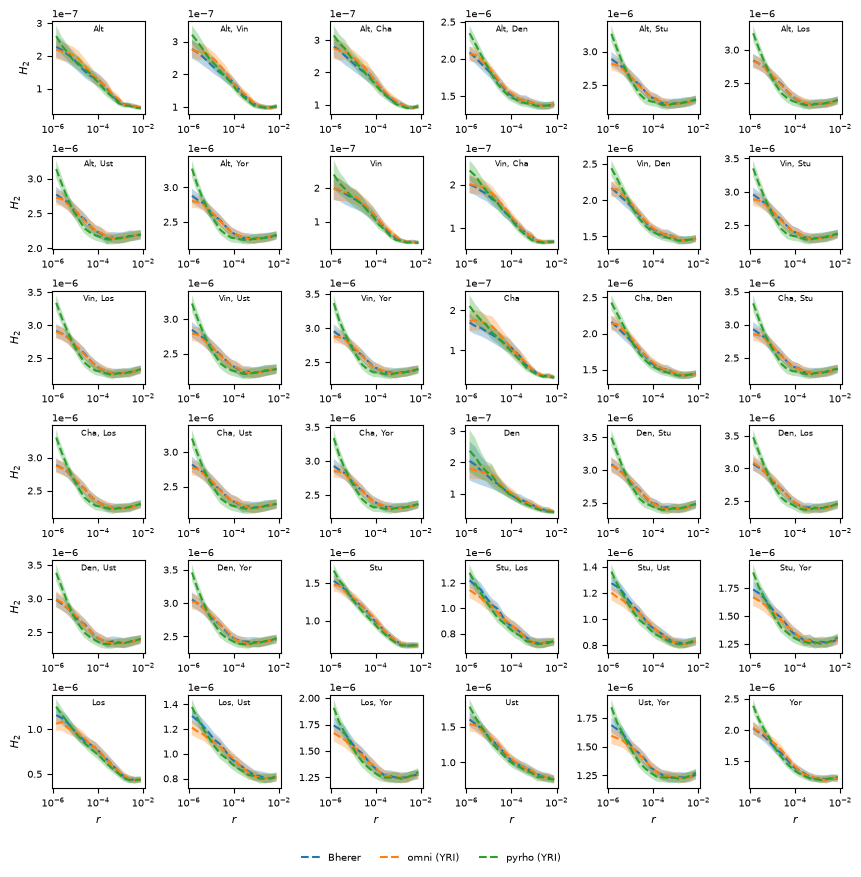

In [5]:
# recombination map figure

pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
stat_labels = []
for i in range(8):
    stat_labels.append(pops[i][:3])
    for j in range(i + 1, 8):
        stat_labels.append(f"{pops[i][:3]}, {pops[j][:3]}")

stats = {}
for var in ["bherer", "omni-YRI", "pyrho-YRI"]:
    with open(f"bootstrapped_data/accessible_1e-4M_ccds_flank_{var}_adj.pkl", "rb") as fin:
        stat = pickle.load(fin)
        stats[var] = h2py.parsing.subset_data(stat, to_pops=pops)


h2py.plotting.plot_h2_curves(
    means=[stats[x]["means"] for x in stats],
    varcovs=[stats[x]["varcovs"] for x in stats],
    stat_labels=stat_labels,
    colors=["tab:blue", "tab:orange", "tab:green"],
    data_labels=["Bherer", "omni (YRI)", "pyrho (YRI)"],
    stats=stats[next(iter(stats))]["stats"][0],
    pops=stats[next(iter(stats))]["pops"],
    r_bins=stats[next(iter(stats))]["bins"],
    fig_size=(8.5, 8.25),
    out_file="../../figures/ld_maps.pdf"
)

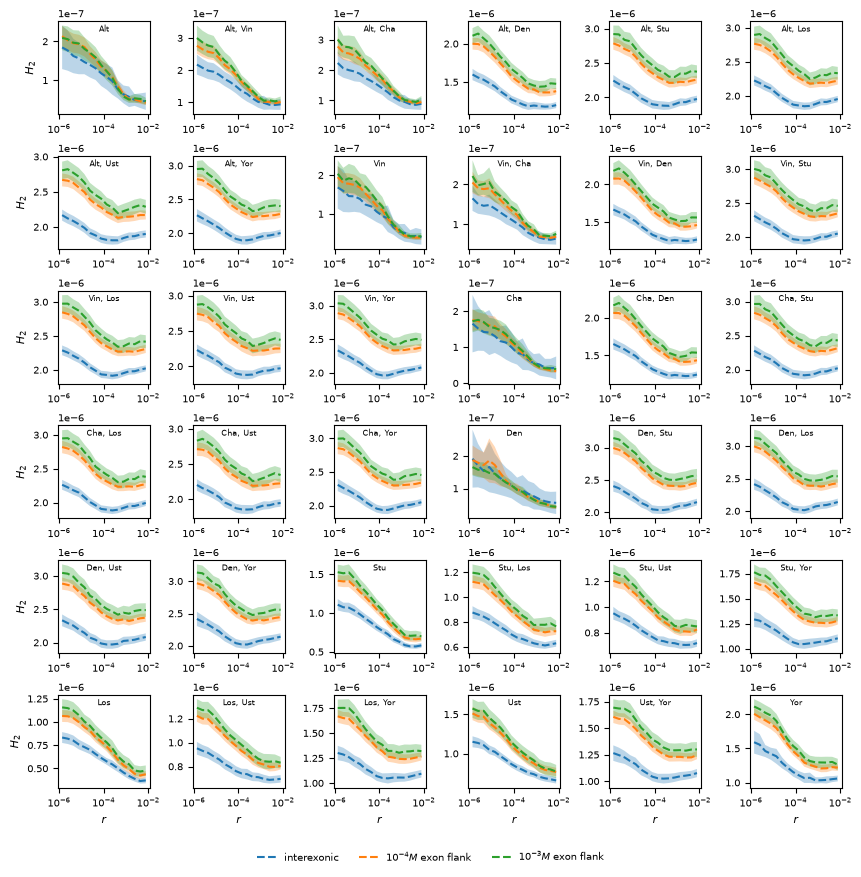

In [11]:
# mask figure

pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
stat_labels = []
for i in range(8):
    stat_labels.append(pops[i][:3])
    for j in range(i + 1, 8):
        stat_labels.append(f"{pops[i][:3]}, {pops[j][:3]}")

stats = {}
for var in ["intergenic", "1e-4M_ccds_flank", "1e-3M_ccds_flank"]:
    with open(f"bootstrapped_data/accessible_{var}_zhou-JHS_adj.pkl", "rb") as fin:
        stat = pickle.load(fin)
        stats[var] = h2py.parsing.subset_data(stat, to_pops=pops)


h2py.plotting.plot_h2_curves(
    means=[stats[x]["means"] for x in stats],
    varcovs=[stats[x]["varcovs"] for x in stats],
    stat_labels=stat_labels,
    colors=["tab:blue", "tab:orange", "tab:green"],
    data_labels=["interexonic", "$10^{-4}M$ exon flank", "$10^{-3}M$ exon flank"],
    stats=stats[next(iter(stats))]["stats"][0],
    pops=stats[next(iter(stats))]["pops"],
    r_bins=stats[next(iter(stats))]["bins"],
    fig_size=(8.5, 8.25),
    out_file="../../figures/masks_M_flanks.pdf"
)

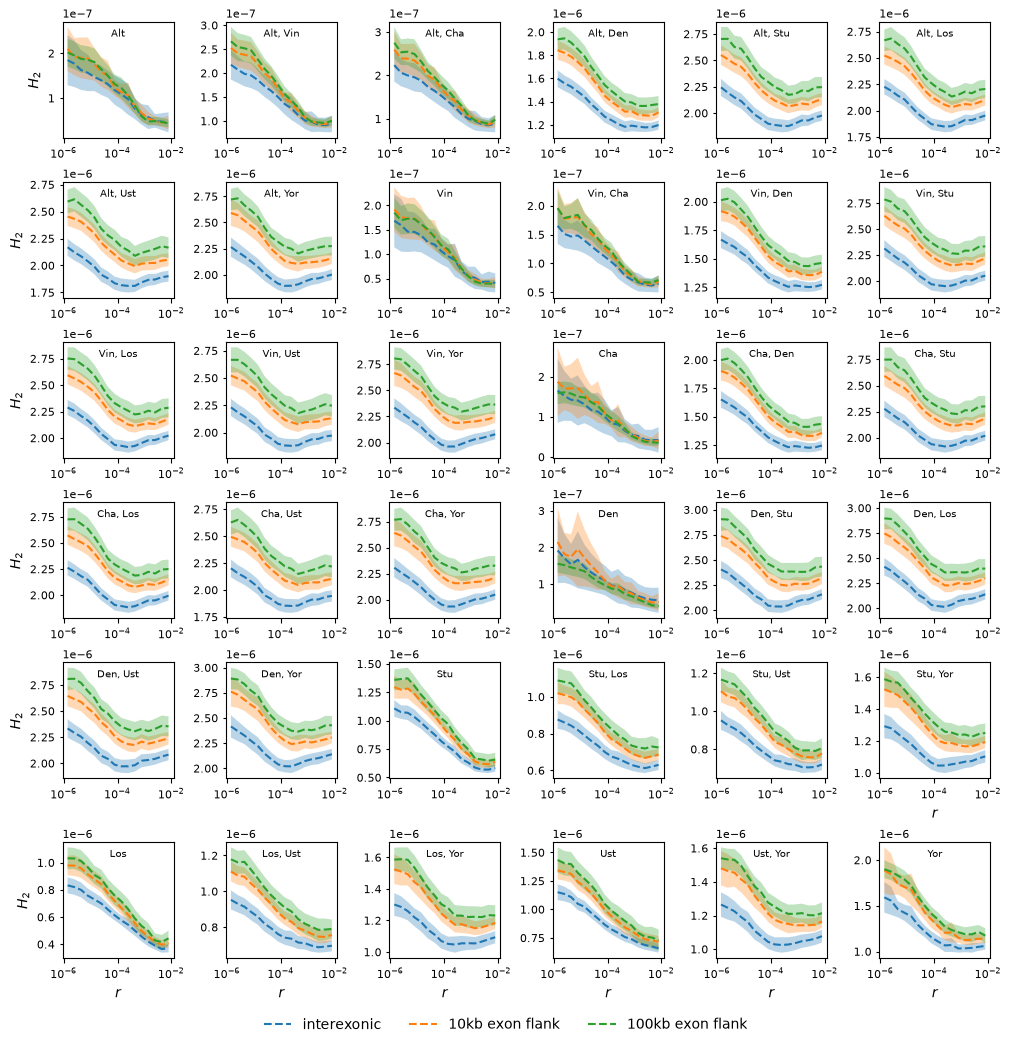

In [8]:
# mask figure

pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
stat_labels = []
for i in range(8):
    stat_labels.append(pops[i][:3])
    for j in range(i + 1, 8):
        stat_labels.append(f"{pops[i][:3]}, {pops[j][:3]}")

stats = {}
for var in ["intergenic", "10kb_ccds_flank", "100kb_ccds_flank"]:
    with open(f"bootstrapped_data/accessible_{var}_zhou-JHS_adj.pkl", "rb") as fin:
        stat = pickle.load(fin)
        stats[var] = h2py.parsing.subset_data(stat, to_pops=pops)


h2py.plotting.plot_h2_curves(
    means=[stats[x]["means"] for x in stats],
    varcovs=[stats[x]["varcovs"] for x in stats],
    stat_labels=stat_labels,
    data_labels=["interexonic", "$10$kb exon flank", "$100$kb exon flank"],
    stats=stats[next(iter(stats))]["stats"][0],
    pops=stats[next(iter(stats))]["pops"],
    r_bins=stats[next(iter(stats))]["bins"],
    fig_size=(10,10),
    out_file="figures/masks_bp_flanks.pdf"
)

In [11]:
# how many windows are there with > 0 sites?
path_spec = f"outputs/stats_accessible_1e-4M_ccds_flank_bherer_chr_{{chrom}}.pkl"
data = {}
for chrom in range(1, 23):
    chrom_file = path_spec.format(chrom=chrom)
    with open(chrom_file, "rb") as fin:
        chrom_data = pickle.load(fin)
        for x in chrom_data:
            if np.sum(chrom_data[x]["denoms"][:-1]) > 0:
                data[x] = chrom_data[x]
print(len(data))

559


In [10]:
for x in data:
    if np.sum(data[x]["denoms"][:-1]) < 1:
        print(x, data[x]["denoms"])

merged.variants.chr9.vcf.gz_9 [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(2.0)]
merged.variants.chr21.vcf.gz_1 [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(1.0)]
